In [ ]:
import pandas as pd

# Load the water dataset
df = pd.read_csv('/content/water_dataset.csv')

# Display the first few rows of the dataframe
display(df.head())

,date,split,location_index,location_id,location_group,Specific_conductance_Max,pH_Max,pH_Min,Specific_conductance_Min,Specific_conductance_Mean,Dissolved_oxygen_Max,Dissolved_oxygen_Mean,Dissolved_oxygen_Min,Temperature_Mean,Temperature_Min,Temperature_Max,pH_Median
0,2016-01-28,train,1,2198840,1,0.001131,0.884615,0.001120,0.001113,0.677632,0.841463,0.765152,0.787402,0.293750,0.298077,0.276163,0.648148
1,2016-01-28,train,2,2198920,1,0.001170,0.871795,0.001159,0.001152,0.703947,0.829268,0.772727,0.795276,0.293750,0.301282,0.276163,0.648148
2,2016-01-28,train,3,2198950,1,0.001326,0.884615,0.001198,0.001250,0.677632,0.853659,0.750000,0.755906,0.300000,0.298077,0.287791,0.648148
3,2016-01-28,train,4,2203603,2,0.014094,0.858974,0.001238,0.003926,0.697368,0.829268,0.772727,0.771654,0.296875,0.294872,0.279070,0.638889
4,2016-01-28,train,5,2203655,2,0.088109,0.858974,0.010766,0.029297,0.684211,0.853659,0.765152,0.755906,0.296875,0.291667,0.281977,0.648148


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Dataset Overview
print("--- Dataset Shape ---")
print(df.shape)
print("\n--- Dataset Info ---")
df.info()
print("\n--- Missing Values Summary ---")
print(df.isnull().sum())

--- Dataset Shape ---
(26085, 17)

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26085 entries, 0 to 26084
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   date                       26085 non-null  object 
 1   split                      26085 non-null  object 
 2   location_index             26085 non-null  int64  
 3   location_id                26085 non-null  int64  
 4   location_group             26085 non-null  int64  
 5   Specific_conductance_Max   26085 non-null  float64
 6   pH_Max                     26085 non-null  float64
 7   pH_Min                     26085 non-null  float64
 8   Specific_conductance_Min   26085 non-null  float64
 9   Specific_conductance_Mean  26085 non-null  float64
 10  Dissolved_oxygen_Max       26085 non-null  float64
 11  Dissolved_oxygen_Mean      26085 non-null  float64
 12  Dissolved_oxygen_Min       26085 non-null  flo

In [ ]:
# 2. Descriptive Statistics
print("--- Descriptive Statistics for Numerical Features ---")
display(df.describe(include='all'))

--- Descriptive Statistics for Numerical Features ---


,date,split,location_index,location_id,location_group,Specific_conductance_Max,pH_Max,pH_Min,Specific_conductance_Min,Specific_conductance_Mean,Dissolved_oxygen_Max,Dissolved_oxygen_Mean,Dissolved_oxygen_Min,Temperature_Mean,Temperature_Min,Temperature_Max,pH_Median
count,26085,26085,26085.000000,2.608500e+04,26085.000000,26085.000000,26085.000000,26085.000000,26085.000000,26085.000000,26085.000000,26085.000000,26085.000000,26085.000000,26085.000000,26085.000000,26085.000000
unique,705,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2018-01-01,train,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,37,15651,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,19.000000,1.138139e+07,1.729730,0.071648,0.887349,0.030986,0.047079,0.550942,0.857237,0.585189,0.557359,0.588324,0.569588,0.581686,0.663508
std,NaN,NaN,10.677283,3.552055e+07,0.501286,0.168408,0.035386,0.122239,0.136686,0.119689,0.031167,0.146308,0.172836,0.200402,0.208671,0.186540,0.029385
min,NaN,NaN,1.000000,2.198840e+06,0.000000,0.000526,0.410256,0.000255,0.000508,0.118421,0.719512,0.068182,0.031496,0.059375,0.022436,0.090116,0.574074
25%,NaN,NaN,10.000000,2.203900e+06,2.000000,0.001910,0.871795,0.001591,0.001777,0.480263,0.841463,0.507576,0.472441,0.421875,0.400641,0.427326,0.648148
50%,NaN,NaN,19.000000,2.336152e+06,2.000000,0.002632,0.884615,0.002220,0.002422,0.546053,0.853659,0.583333,0.566929,0.600000,0.580128,0.595930,0.657407
75%,NaN,NaN,28.000000,2.337170e+06,2.000000,0.005497,0.910256,0.003713,0.004902,0.631579,0.878049,0.689394,0.677165,0.753125,0.740385,0.738372,0.675926


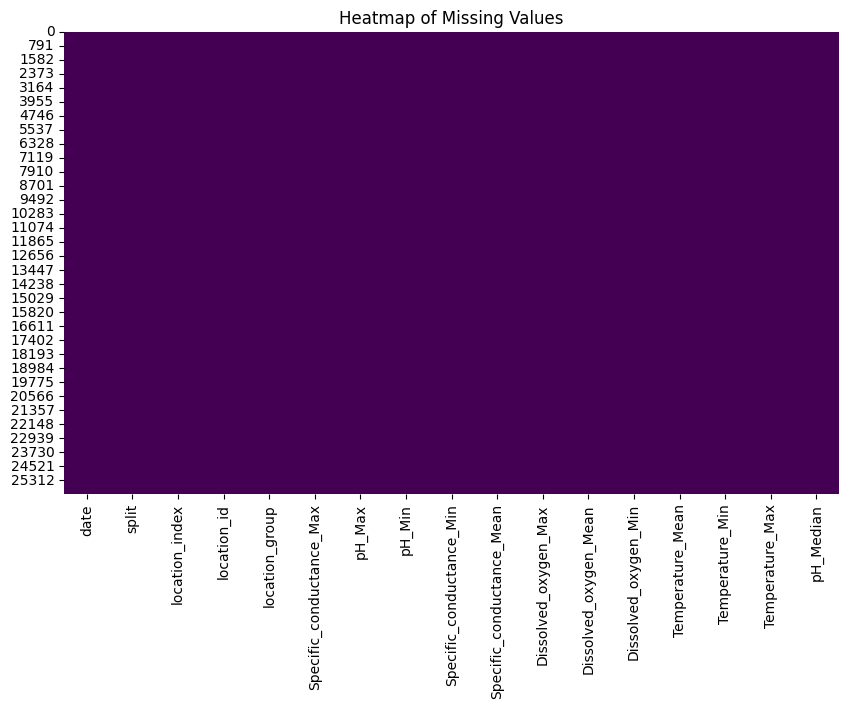

In [ ]:
# 3. Visualizing Missing Data
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Heatmap of Missing Values')
plt.show()

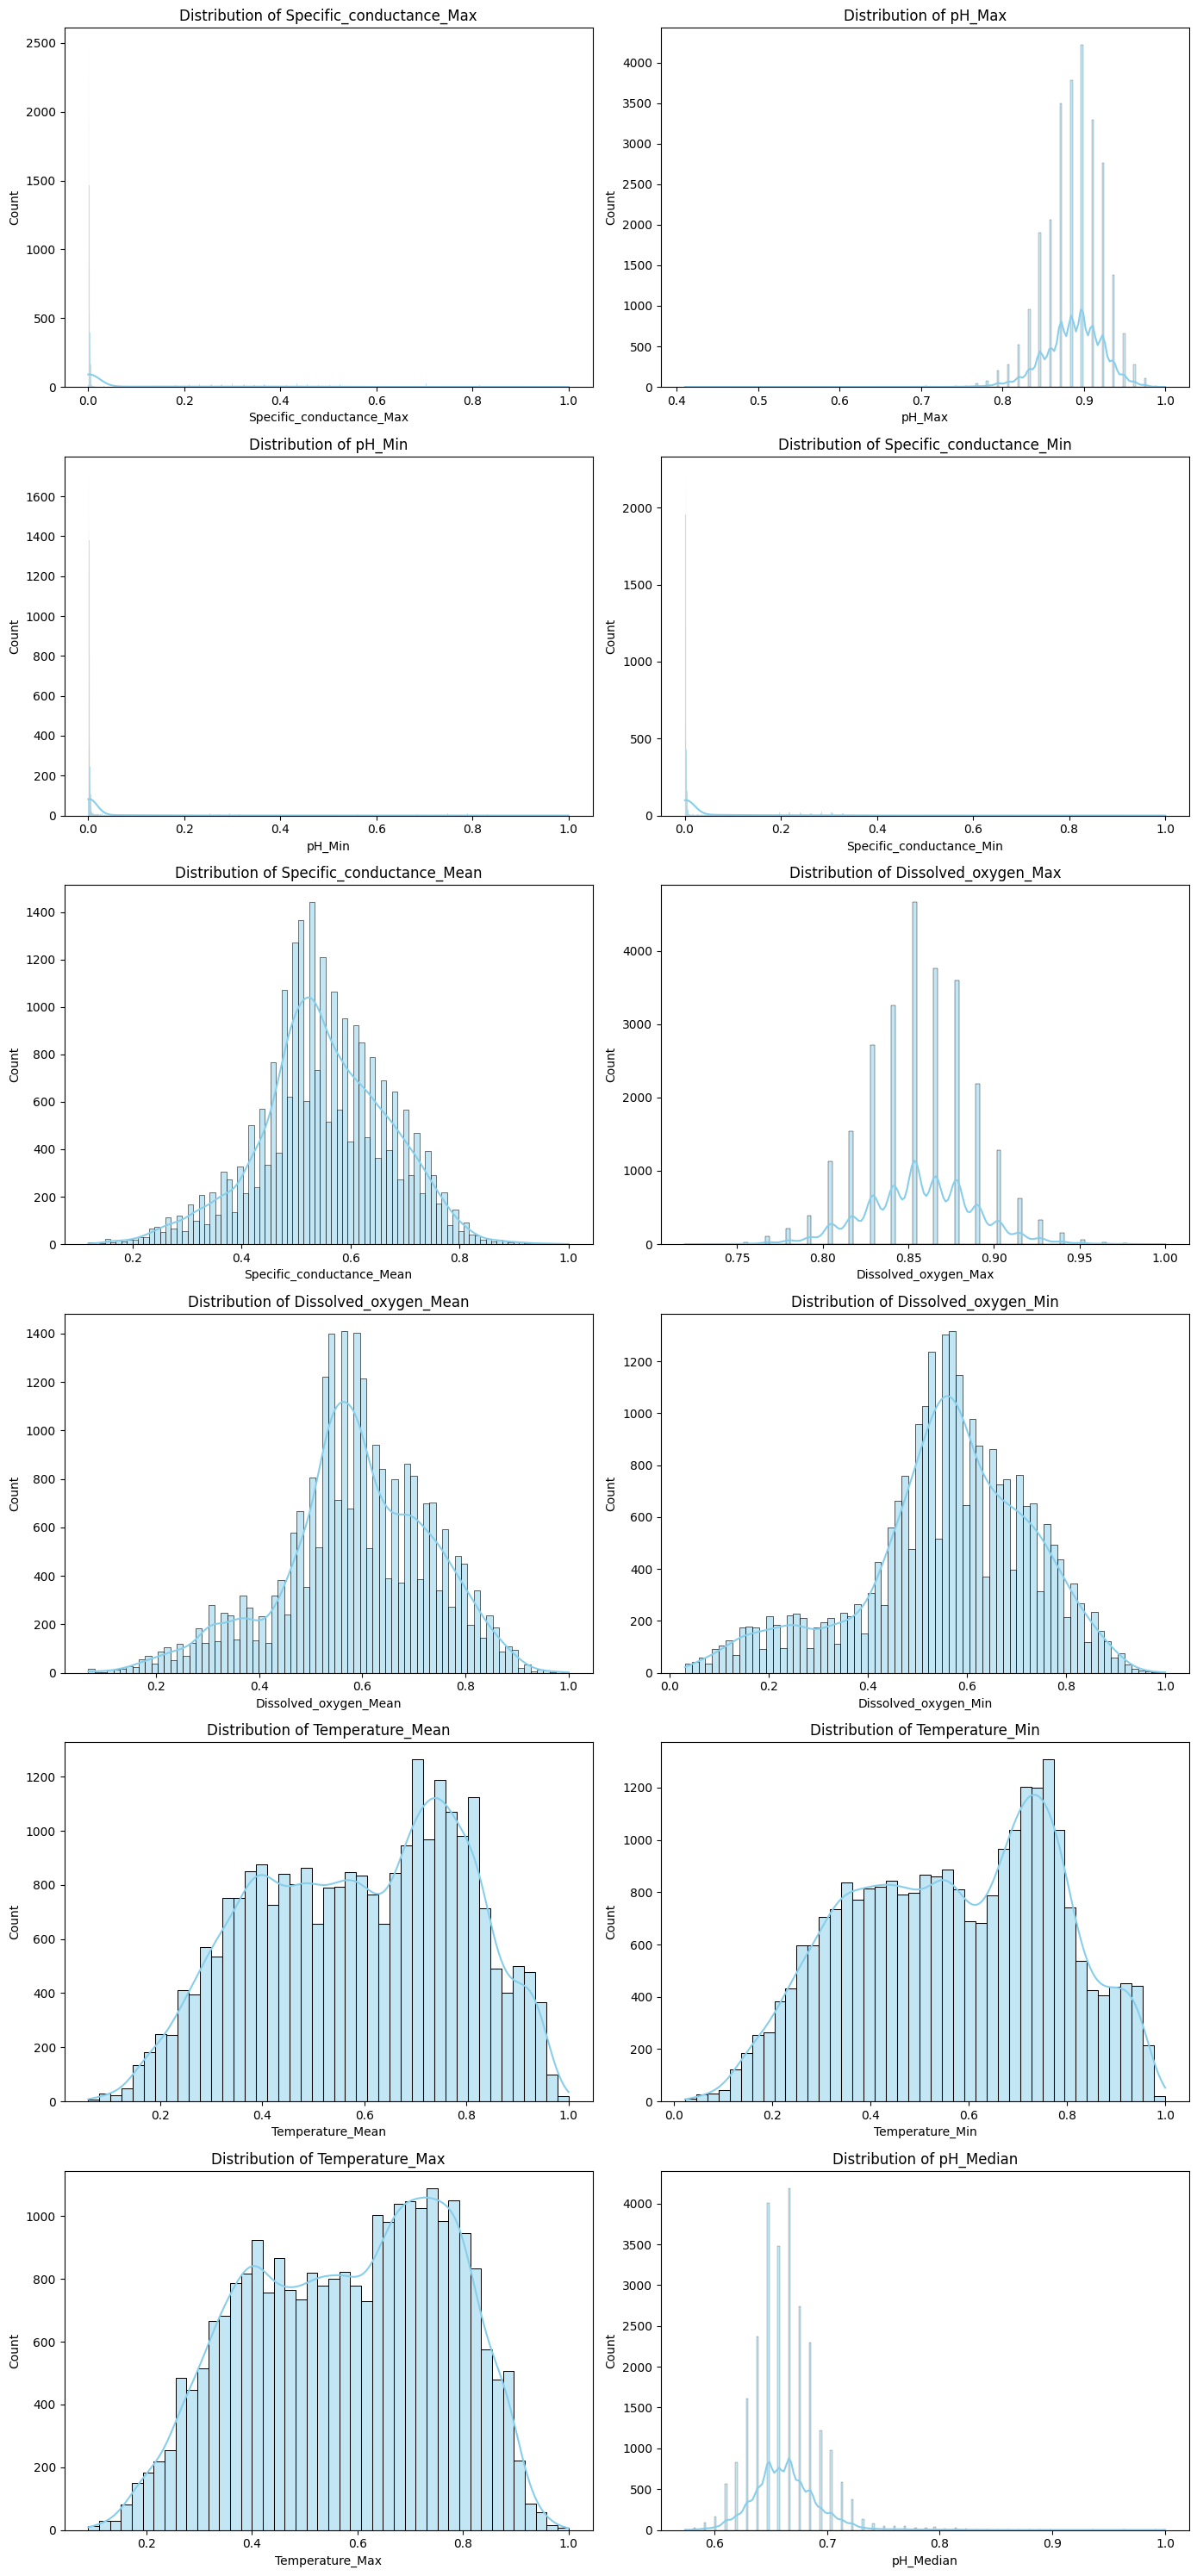

In [ ]:
# 4. Distribution of Numerical Features
numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns

# Exclude index-like or group columns from plot if there are too many
cols_to_plot = [col for col in numerical_cols if 'id' not in col.lower() and 'index' not in col.lower() and 'group' not in col.lower()]

if cols_to_plot:
    fig, axes = plt.subplots(nrows=(len(cols_to_plot) + 1) // 2, ncols=2, figsize=(14, len(cols_to_plot) * 2.5))
    axes = axes.flatten()
    for i, col in enumerate(cols_to_plot):
        sns.histplot(df[col].dropna(), ax=axes[i], kde=True, color='skyblue')
        axes[i].set_title(f'Distribution of {col}')

    # Hide any unused subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
    plt.tight_layout()
    plt.show()
else:
    print("No matching numerical columns found to plot.")

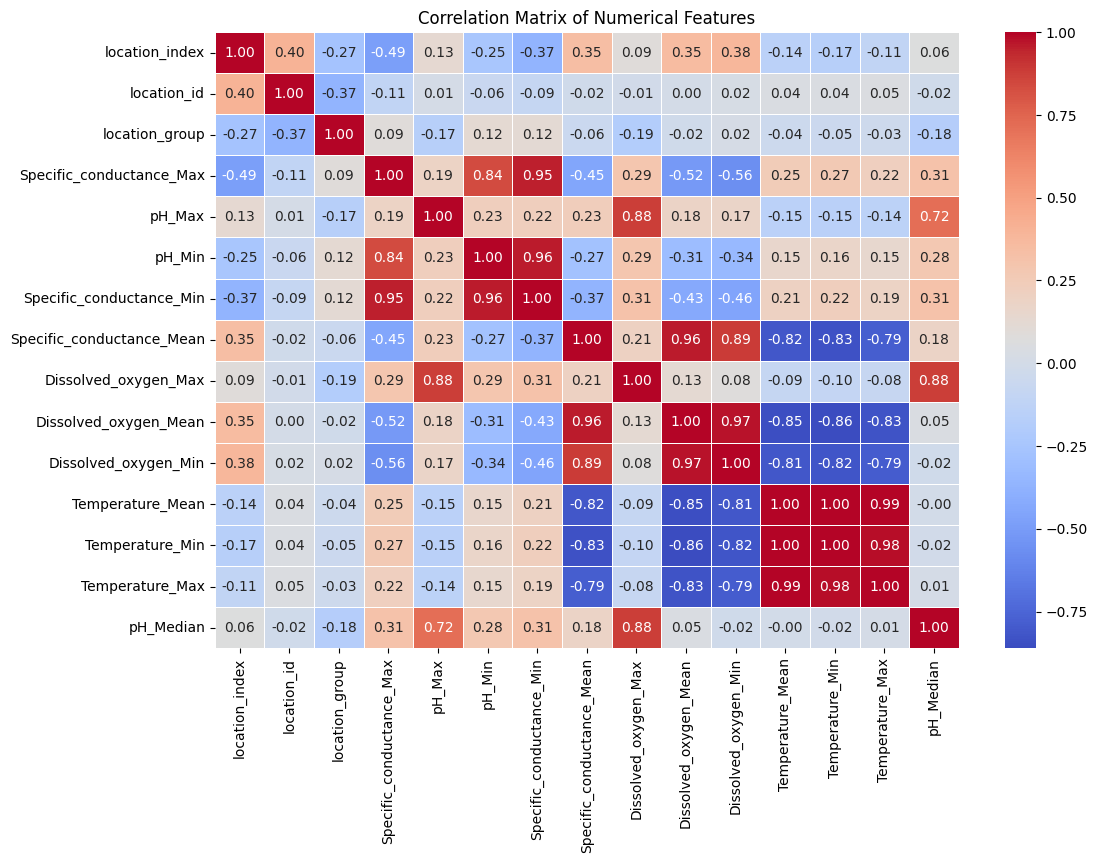

In [ ]:
# 5. Correlation Heatmap
plt.figure(figsize=(12, 8))
numeric_df = df.select_dtypes(include=['float64', 'int64'])
correlation_matrix = numeric_df.corr()
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

In [ ]:
# Check the unique values in the 'split' column
print("Unique values in 'split' column:")
print(df['split'].value_counts() if hasattr(df['split'], 'value_counts') else df['split'].unique())

# Also let's check how many samples we have per split
print(df['split'].value_counts())

Unique values in 'split' column:
split
train    15651
test     10434
Name: count, dtype: int64
split
train    15651
test     10434
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

# If we want to split based on the existing 'split' column:
train_df = df[df['split'] == 'train'].copy()
test_df = df[df['split'] != 'train'].copy()

print(f"Using pre-defined split:")
print(f"Training set shape: {train_df.shape}")
print(f"Testing set shape: {test_df.shape}")

# Alternatively, performing a standard random 80/20 train-test split on features (X) and target (y)
# Let's assume we separate features and targets if needed. For now, we split the DataFrame directly.
train_random, test_random = train_test_split(df, test_size=0.2, random_state=42)
print(f"\nUsing random 80/20 split:")
print(f"Random training set shape: {train_random.shape}")
print(f"Random testing set shape: {test_random.shape}")

Using pre-defined split:
Training set shape: (15651, 17)
Testing set shape: (10434, 17)

Using random 80/20 split:
Random training set shape: (20868, 17)
Random testing set shape: (5217, 17)


In [ ]:
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score
import numpy as np

# Define the numerical features to use for anomaly detection
features = ['Specific_conductance_Max', 'pH_Max', 'pH_Min',
            'Specific_conductance_Min', 'Specific_conductance_Mean',
            'Dissolved_oxygen_Max', 'Dissolved_oxygen_Mean',
            'Dissolved_oxygen_Min', 'Temperature_Mean',
            'Temperature_Min', 'Temperature_Max', 'pH_Median']

# Scale the features
scaler = StandardScaler()
X_train = scaler.fit_transform(train_df[features])
X_test = scaler.transform(test_df[features])

print("Training Isolation Forest...")
# Train Isolation Forest (unsupervised)
iso_forest = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)
iso_forest.fit(X_train)

# Predict anomalies (-1 for anomaly, 1 for normal)
y_pred_train_if = iso_forest.predict(X_train)
y_pred_test_if = iso_forest.predict(X_test)

# Convert to binary labels (1 for anomaly, 0 for normal) for standard classification tasks
y_train_labels = np.where(y_pred_train_if == -1, 1, 0)
y_test_labels = np.where(y_pred_test_if == -1, 1, 0)

print(f"Anomalies detected in train set: {sum(y_train_labels)} out of {len(y_train_labels)}")
print(f"Anomalies detected in test set: {sum(y_test_labels)} out of {len(y_test_labels)}")

Training Isolation Forest...
Anomalies detected in train set: 783 out of 15651
Anomalies detected in test set: 650 out of 10434


In [ ]:
print("Training Logistic Regression...")
# Train Logistic Regression to predict the anomalies identified by the Isolation Forest
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train, y_train_labels)

# Evaluate Logistic Regression
y_pred_log_reg = log_reg.predict(X_test)

print("\n--- Logistic Regression Classification Report ---")
print(classification_report(y_test_labels, y_pred_log_reg))
print(f"Accuracy Score: {accuracy_score(y_test_labels, y_pred_log_reg):.4f}")

Training Logistic Regression...

--- Logistic Regression Classification Report ---
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      9784
           1       0.88      0.65      0.75       650

    accuracy                           0.97     10434
   macro avg       0.93      0.82      0.87     10434
weighted avg       0.97      0.97      0.97     10434

Accuracy Score: 0.9728


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# Initialize the models
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
}

# Dictionary to store predictions
predictions = {}

# Train and evaluate each model
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train_labels)
    predictions[name] = model.predict(X_test)
    print(f"{name} completed.")

Training Decision Tree...
Decision Tree completed.
Training Random Forest...
Random Forest completed.
Training XGBoost...


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:09:42] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost completed.


In [ ]:
# Evaluate the models and print reports
for name, preds in predictions.items():
    print(f"\n================ {name} Evaluation ================")
    print(classification_report(y_test_labels, preds))
    print(f"Accuracy Score: {accuracy_score(y_test_labels, preds):.4f}")


================ Decision Tree Evaluation ================
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      9784
           1       0.89      0.83      0.86       650

    accuracy                           0.98     10434
   macro avg       0.94      0.91      0.92     10434
weighted avg       0.98      0.98      0.98     10434

Accuracy Score: 0.9828

================ Random Forest Evaluation ================
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      9784
           1       0.95      0.83      0.89       650

    accuracy                           0.99     10434
   macro avg       0.97      0.91      0.94     10434
weighted avg       0.99      0.99      0.99     10434

Accuracy Score: 0.9868

================ XGBoost Evaluation ================
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      9784
           1     

In [ ]:
from sklearn.metrics import classification_report, accuracy_score

# Evaluate and compare train vs test metrics for each model
for name, model in models.items():
    # Predict on train and test datasets
    train_preds = model.predict(X_train)
    test_preds = predictions[name]

    train_acc = accuracy_score(y_train_labels, train_preds)
    test_acc = accuracy_score(y_test_labels, test_preds)

    print(f"================ {name} Evaluation ================")
    print(f"Training Accuracy: {train_acc:.4f}  |  Testing Accuracy: {test_acc:.4f}\n")

    print("--- Training Classification Report ---")
    print(classification_report(y_train_labels, train_preds))

    print("--- Testing Classification Report ---")
    print(classification_report(y_test_labels, test_preds))
    print("\n" + "="*50 + "\n")

================ Decision Tree Evaluation ================
Training Accuracy: 1.0000  |  Testing Accuracy: 0.9828

--- Training Classification Report ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     14868
           1       1.00      1.00      1.00       783

    accuracy                           1.00     15651
   macro avg       1.00      1.00      1.00     15651
weighted avg       1.00      1.00      1.00     15651

--- Testing Classification Report ---
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      9784
           1       0.89      0.83      0.86       650

    accuracy                           0.98     10434
   macro avg       0.94      0.91      0.92     10434
weighted avg       0.98      0.98      0.98     10434



================ Random Forest Evaluation ================
Training Accuracy: 1.0000  |  Testing Accuracy: 0.9868

--- Training Classification Report --

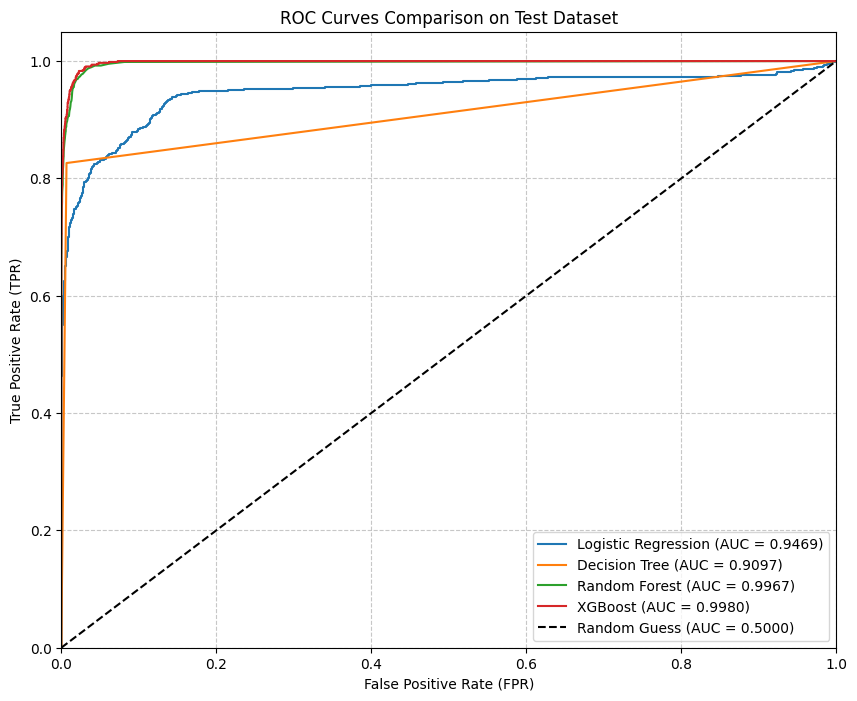

--- ROC-AUC Scores (Test Dataset) ---
Logistic Regression: 0.9469
Decision Tree: 0.9097
Random Forest: 0.9967
XGBoost: 0.9980


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Gather prediction probabilities for class 1 (Anomaly)
model_probs = {}

# Logistic Regression
if 'log_reg' in globals():
    model_probs['Logistic Regression'] = log_reg.predict_proba(X_test)[:, 1]

# Tree and Ensemble models
for name, model in models.items():
    model_probs[name] = model.predict_proba(X_test)[:, 1]

# Plot ROC Curves
plt.figure(figsize=(10, 8))

for name, probs in model_probs.items():
    auc_score = roc_auc_score(y_test_labels, probs)
    fpr, tpr, _ = roc_curve(y_test_labels, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.4f})")

# Plot random guess line
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.5000)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curves Comparison on Test Dataset')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# Print AUC scores
print("--- ROC-AUC Scores (Test Dataset) ---")
for name, probs in model_probs.items():
    auc_score = roc_auc_score(y_test_labels, probs)
    print(f"{name}: {auc_score:.4f}")

In [ ]:
import pickle
from google.colab import files

# Save Logistic Regression model
log_reg_filename = 'logistic_regression_model.pkl'
with open(log_reg_filename, 'wb') as f:
    pickle.dump(log_reg, f)
print(f"Saved {log_reg_filename}")

# Save Random Forest model
rf_filename = 'random_forest_model.pkl'
with open(rf_filename, 'wb') as f:
    pickle.dump(models['Random Forest'], f)
print(f"Saved {rf_filename}")

# Save XGBoost model
xgb_filename = 'xgboost_model.pkl'
with open(xgb_filename, 'wb') as f:
    pickle.dump(models['XGBoost'], f)
print(f"Saved {xgb_filename}")

# Trigger browser downloads for each model
for file_path in [log_reg_filename, rf_filename, xgb_filename]:
    files.download(file_path)

Saved logistic_regression_model.pkl
Saved random_forest_model.pkl
Saved xgboost_model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>